- Backbone  : ViT-Small/16 (≈22 M params, ImageNet pretrained)  
- Clients   : 5 clinets (Dirichlet-α = 0.1 skewed)  
- Dataset : DTD (1880 images (train))
- Epochs    : 3 per client  |  Batch size: 64  |  Checkpoints every epoch  

### 0. Google-Drive mount (skip on local Jupyter)

In [20]:
from google.colab import drive
drive.mount('/content/drive')

# ROOT_PATH = "/content/drive/MyDrive/Graduation Thesis/fl_localize_stitch_vit/"
ROOT_PATH = "/content/drive/Othercomputers/Victus/Disk D/New Uzb Semester 8/Graduation Thesis/fl_localize_stitch_vit/"
# ROOT_PATH = "./"              # to run locally

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


#### 0a. Dependencies

In [4]:
import subprocess, sys, importlib, pathlib, os

PKGS = ["torch", "torchvision", "timm", "tqdm"]
for pkg in PKGS:
    try:
        importlib.import_module(pkg)
    except ModuleNotFoundError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", pkg])

In [21]:
ROOT_PATH = pathlib.Path(ROOT_PATH).resolve()
sys.path.extend([str(ROOT_PATH)])

ckpt_dir = ROOT_PATH / "checkpoints"
ckpt_dir.mkdir(exist_ok=True)

### 1. Hyper-parameters & torchvision transforms  

In [6]:
NUM_CLIENTS = 5
BACKBONE_NAME = "vit_small_patch16_224"  # ~22 M parameters
BATCH_SIZE  = 64
IMG_SIZE    = 224    # ViT default patch‑16 grid
ALPHA       = 0.1    # Dirichlet concentration → stronger skew < 1, weaker skew > 1
SUBSET_FRAC = 0.5
DATASET     = "DTD"
SEED        = 42

FEDADAM_LR    = 1e-2  # Server learning rate; tune using validation data
FEDADAM_BETA1 = 0.9
FEDADAM_BETA2 = 0.99
FEDADAM_TAU   = 1e-3

import timm
from torchvision import transforms

pretrained_cfg = timm.get_pretrained_cfg(BACKBONE_NAME)

preprocess = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    # transforms.Lambda(lambda x: x.expand(3, -1, -1)),        # 1-→3 channels          # DTD is already 3-channel (3, H, W).
    transforms.Normalize(pretrained_cfg.mean, pretrained_cfg.std),
])

### 2. Data loading (with sub-sampling) & skewed client splits

In [7]:
from torch.utils.data import DataLoader, Subset
import torch, numpy as np

torch.manual_seed(SEED)

DATA_ROOT = "./data"
def make_dataset(name, subset_frac=SUBSET_FRAC, seed=SEED):
    if name == "EuroSAT":
        from torchvision.datasets import EuroSAT
        # Load the full dataset once
        full_dataset = EuroSAT(DATA_ROOT, transform=preprocess, download=True)
        # Split into 80% train / 20% test
        train_size = int(0.8 * len(full_dataset))
        test_size  = len(full_dataset) - train_size
        train, test = torch.utils.data.random_split(full_dataset, [train_size, test_size])

    elif name == "DTD":
        from torchvision.datasets import DTD
        train = DTD(DATA_ROOT, split="train",        download=True, transform=preprocess)
        val   = DTD(DATA_ROOT, split="val",          download=True, transform=preprocess)
        test  = DTD(DATA_ROOT, split="test",         download=True, transform=preprocess)

    # elif name == "RESISC45":
    #     from torchvision.datasets import RESISC45
    #     train = RESISC45(DATA_ROOT, split="train",   download=True, transform=preprocess)
    #     test  = RESISC45(DATA_ROOT, split="test",    download=False, transform=preprocess)

    elif name == "StanfordCars":
        from torchvision.datasets import StanfordCars
        train = StanfordCars(DATA_ROOT, split="train",       download=True, transform=preprocess)
        test  = StanfordCars(DATA_ROOT, split="test",        download=True, transform=preprocess)

    else:
        raise ValueError("Unknown dataset")

    if name != "DTD":
        val_size = max(1, len(train) // 5)
        train, val = torch.utils.data.random_split(
            train, [len(train) - val_size, val_size],
            generator=torch.Generator().manual_seed(seed))

    return train, val, test


# Dirichlet split
def create_skewed_clients(dataset, num_clients=NUM_CLIENTS, alpha=ALPHA, seed=SEED):
    """
    Returns:
        clients_indices: list of lists of indices for each client
        num_classes: number of classes in the dataset
    """
    rng = np.random.default_rng(seed)

    if hasattr(dataset, "targets"):
        labels = np.array(dataset.targets)
    else:
        labels = np.array([y for _, y in dataset])

    classes = np.unique(labels)
    class_indices = [np.where(labels == c)[0] for c in classes]
    clients = [[] for _ in range(num_clients)]
    for class_i in class_indices:
        rng.shuffle(class_i)
        parts = rng.dirichlet(alpha * np.ones(num_clients))
        splits = (np.cumsum(parts) * len(class_i)).astype(int)[:-1]
        for cli, chunk in zip(clients, np.split(class_i, splits)):
            cli.extend(chunk)
    return clients, len(classes)


train_ds, val_ds, test_ds = make_dataset(DATASET)

client_indices, NUM_CLASSES = create_skewed_clients(train_ds)
make_loader = lambda subset: DataLoader(subset, batch_size=BATCH_SIZE,
                                        shuffle=True, num_workers=2, pin_memory=True)
train_loaders = [make_loader(Subset(train_ds, idx)) for idx in client_indices]
client_sizes = [len(loader.dataset) for loader in train_loaders]   # for weighted FedAvg

val_loader    = DataLoader(val_ds, batch_size=256, shuffle=False,
                            num_workers=2, pin_memory=True)

test_loader   = DataLoader(test_ds, batch_size=256, shuffle=False,
                            num_workers=2, pin_memory=True)

print(f"{DATASET}: {len(train_ds):5d} train   {len(val_ds):5d} val   {len(test_ds):5d} test   {NUM_CLASSES} classes")

100%|██████████| 625M/625M [00:23<00:00, 26.5MB/s]


DTD:  1880 train    1880 val    1880 test   47 classes


### 3. ViT-Small/16 model

In [8]:
import copy
import timm, torch.nn as nn

def make_classifier(num_classes: int = NUM_CLASSES):
    model = timm.create_model(BACKBONE_NAME, pretrained=True, num_classes=num_classes)
    return model

pretrained_model = make_classifier().cpu().eval()

model.safetensors: reconstructing file:   0%|          |  0.00B / 88.2MB            

model.safetensors: downloading bytes:           |  0.00B            

### 4. Train Clients

In [9]:
from torch.optim import AdamW
from torch.nn.functional import cross_entropy
from tqdm import tqdm

def train_model(model, loader, client_id, epochs=1, device="cuda"):
    model.to(device)

    opt = AdamW(model.parameters(), lr=3e-4)
    scaler = torch.amp.GradScaler('cuda')

    for ep in range(1, epochs+1):
        model.train()

        pbar = tqdm(loader, desc=f"Client{client_id} Epoch{ep}")
        for x, y in pbar:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            opt.zero_grad()

            with torch.amp.autocast('cuda'):
                out = model(x)
                loss = cross_entropy(out, y)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()

        # Checkpoint
        torch.save(model.state_dict(), ckpt_dir / f"client{client_id}_epoch{ep}.pt")

    return model.cpu().eval()          # leave in eval mode!

In [22]:
# Train all clients
client_models = []
for cid, ld in enumerate(train_loaders):
    client_models.append(train_model(copy.deepcopy(pretrained_model), ld, cid))

Client4 Epoch1: 100%|██████████| 8/8 [00:03<00:00,  2.37it/s]


#### Or load weights (state dict) from a checkpoint:

In [ ]:
client_models = []
ckpt_dir = pathlib.Path(ROOT_PATH) / "checkpoints"

for cid in range(NUM_CLIENTS):
    model = timm.create_model(BACKBONE_NAME, num_classes=NUM_CLASSES)

    client_ckpt = f"client{cid}_epoch1.pt"
    state = torch.load(ckpt_dir / client_ckpt, map_location="cpu")

    model.load_state_dict(state, strict=True)
    client_models.append(model.eval())

#### 4a. Evaluate clients separately

Evaluate the clients trained on **imbalanced data** using the held-out validation split:

In [23]:
def accuracy(model, loader):
    model.eval().cuda()
    preds, labels = [], []

    with torch.no_grad():
        for x, y in loader:
            preds.extend(model(x.cuda()).argmax(1).cpu().numpy())
            labels.extend(y.numpy())
    model.cpu()
    return (np.array(preds) == np.array(labels)).mean()

In [24]:
import copy

print("Client validation accuracies:")

for cid, (clmodel, ld) in enumerate(zip(client_models, train_loaders)):
    acc   = accuracy(clmodel, val_loader)
    print(f"  client{cid}:  {acc:.4f}")

Client validation accuracies:
  client0:  0.2495
  client1:  0.0479
  client2:  0.1633
  client3:  0.2117
  client4:  0.1947


In [25]:
print("Client initial train dataset sizes:")

for i, ld in enumerate(train_loaders):
    print(f"  client{i}:  {len(ld.dataset)}")

Client initial train dataset sizes:
  client0:  580
  client1:  135
  client2:  276
  client3:  431
  client4:  458


### 5. Localizer

In [26]:
import torch
from typing import Dict, List

class SimpleLocalizer:
    def __init__(self, pretrained: nn.Module, finetuned: nn.Module, K=0.95):
        # Task vector τ = θ_finetuned − θ_pretrained
        self.task_vector = {n: (f.detach() - p.detach())     # task vector
                      for (n, p), (_, f) in zip(pretrained.named_parameters(),
                                                finetuned.named_parameters())}

        # Global threshold for top-k magnitude
        all_vals = torch.cat([task_vector.flatten().abs() for task_vector in self.task_vector.values()])

        # add normal noise
        # all_vals = all_vals + torch.normal(mean=0, std=torch.std(all_vals) * 0.04, size=all_vals.shape)

        k = max(1, int(K * all_vals.numel()))    # max() is for safety: to choose at least one
        thresh = torch.topk(all_vals, k).values[-1]     # topk() returns namedtuple(values: List, indices: List) in decreasing order. So thresh is the minimum in the top-k or top-95% elements.

        # Masked task vector: γ ⊙ τ
        self.masks = {n: (task_vector.abs() >= thresh) for n, task_vector in self.task_vector.items()}
        self.masked_task_vector = {n: (task_vector * self.masks[n]).clone()
                                   for n, task_vector in self.task_vector.items()}

In [27]:
masked_task_vectors = []
masks = []
pretrained_copy = copy.deepcopy(pretrained_model)

for cid, clmodel in enumerate(client_models):
    print(f"Localizing client {cid}")
    localizer = SimpleLocalizer(pretrained_copy, clmodel, K=0.95)
    masked_task_vectors.append(localizer.masked_task_vector)
    masks.append(localizer.masks)

Localizing client 0
Localizing client 1
Localizing client 2
Localizing client 3
Localizing client 4


### 6. Stitch task vectors
top-K% largest magnitude weights, Yadav et al. 2023

In [28]:
import copy
def simpleStitcher(base_model: nn.Module, masked_task_vectors: List[Dict[str, torch.Tensor]],
                   masks: List[Dict[str, torch.Tensor]]):
    new_model = copy.deepcopy(base_model)
    new_model_state_dict = new_model.state_dict()

    # Average each coordinate over clients whose masks select it.
    for n in masked_task_vectors[0]:
        numerator = sum(client_masked_task_vector[n] for client_masked_task_vector in masked_task_vectors)
        denominator = torch.zeros_like(numerator)
        ## denominator += NUM_CLIENTS

        ## a = masked_task_vectors[0][n] != 0
        ## denominator += a
        ## print(denominator);break

        for mask in masks:
            denominator += mask[n].to(denominator.dtype)
        denominator.clamp_min_(1)
        new_model_state_dict[n] += numerator / denominator

    new_model.load_state_dict(new_model_state_dict, strict=True)

    return new_model.eval()

In [29]:
stitched_model = simpleStitcher(pretrained_copy, masked_task_vectors, masks)

### 7.  Baselines

#### a. Centralized Baseline Model

A single model trained on the union of all client data.

In [30]:
CENTRAL_EPOCHS = 12

full_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=2, pin_memory=True)

baseline_model = train_model(make_classifier(), full_loader, "Baseline", epochs=CENTRAL_EPOCHS)

ClientBaseline Epoch12: 100%|██████████| 30/30 [00:12<00:00,  2.41it/s]


Or load from a checkpoint:

In [ ]:
ckpt_dir = pathlib.Path(ROOT_PATH) / "checkpoints"

baseline_model = timm.create_model(BACKBONE_NAME, num_classes=NUM_CLASSES)
baseline_ckpt = f"centralizedBaseline_{DATASET}_epoch{CENTRAL_EPOCHS}.pt"

state = torch.load(ckpt_dir / baseline_ckpt, map_location="cpu")
baseline_model.load_state_dict(state, strict=True)


#### b. FedAvg (weighted by client sample counts)

In [31]:
def weight_average(models, client_sizes):
    avg = copy.deepcopy(models[0])
    total_size = sum(client_sizes)
    with torch.no_grad():
        for k in avg.state_dict().keys():
            avg.state_dict()[k].copy_(
                sum(m.state_dict()[k] * (size / total_size) for m, size in zip(models, client_sizes))
            )
    return avg

fedavg_model  = weight_average(client_models, client_sizes).eval()

#### c. FedAdam

Uses the same local AdamW training as the other methods. The server follows [Algorithm 5](https://arxiv.org/html/2003.00295v5) with sample-weighted client updates and moments retained across rounds.


In [32]:
def fedadam_update(base_model, models, client_sizes, moments=None):
    new_model = copy.deepcopy(base_model)
    averaged_model = weight_average(models, client_sizes)
    base_parameters = dict(base_model.named_parameters())
    averaged_parameters = dict(averaged_model.named_parameters())
    if moments is None:
        moments = {name: (torch.zeros_like(parameter),
                          torch.full_like(parameter, FEDADAM_TAU ** 2))
                   for name, parameter in base_parameters.items()}

    # FedAdam server update (Algorithm 5): no bias correction.
    with torch.no_grad():
        for name, parameter in new_model.named_parameters():
            mean_update = averaged_parameters[name] - base_parameters[name]
            m, v = moments[name]
            m.mul_(FEDADAM_BETA1).add_(mean_update, alpha=1 - FEDADAM_BETA1)
            v.mul_(FEDADAM_BETA2).addcmul_(mean_update, mean_update, value=1 - FEDADAM_BETA2)
            parameter.addcdiv_(m, v.sqrt() + FEDADAM_TAU, value=FEDADAM_LR)

    return new_model.eval(), moments

fedadam_model, fedadam_moments = fedadam_update(pretrained_model, client_models, client_sizes)


#### Validation evaluation

In [33]:
fedavg_acc = accuracy(fedavg_model, val_loader)
fedavg_acc

np.float64(0.32978723404255317)

In [34]:
fedadam_acc = accuracy(fedadam_model, val_loader)
fedadam_acc

np.float64(0.1696808510638298)

In [35]:
stitched_acc = accuracy(stitched_model, val_loader)
stitched_acc

np.float64(0.31329787234042555)

In [36]:
baseline_acc = accuracy(baseline_model, val_loader)
baseline_acc

np.float64(0.7106382978723405)

### 8. Simulate Multi-Round Communication merging with the LaS algorithm, FedAvg, FedAdam

**Adaptive retention schedule.** After the initial merge,

$$
K_t = 1 - \mu A_{t-1}^{\mathrm{val}}, \qquad \mu = 0.035.
$$

$A_{t-1}^{\mathrm{val}}$ is validation accuracy as a fraction in $[0,1]$, not a percentage. $K_t$ is the fraction of task-vector coordinates to retain; the nominal discarded fraction is $1-K_t=\mu A_{t-1}^{\mathrm{val}}$.

- The initial merge uses $K_0=0.95$. Initial retention $K_0$ and sensitivity $\mu$ are the configurable hyperparameters; later $K_t$ values are computed from validation accuracy.
- With $\mu=0.035$, later retention lies in $[0.965,1]$, targeting at most 3.5% pruning. For example, accuracy $0.70$ gives $K_t=0.9755$: retain 97.55%, discard 2.45%. The initial merge's 5% pruning is separate from this schedule.
- Larger $\mu$ makes pruning stronger; $\mu=0$ retains all coordinates in later rounds. Increasing pruning as validation accuracy improves is a heuristic, not a guarantee that the discarded updates are unnecessary.
- The current run does not establish $0.035$ as optimal. Tune $K_0$ and $\mu$ using validation data only, and compare against $\mu=0$ and fixed-$K$ runs across seeds to isolate the schedule's effect.

Top-$K$ retention already exists in Dataless LaS; our adaptation makes retention depend on the previous round's validation accuracy.


In [37]:
ROUNDS = 12 - 1   # already did one round above
fedavg_accuracy = [fedavg_acc]
stitched_accuracy = [stitched_acc]
fedadam_accuracy = [fedadam_acc]

for i in range(ROUNDS):
    # Train: Reuse the fixed client datasets and evaluation loaders created above
    client_models_las = []
    for cid, ld in enumerate(train_loaders):
        client_models_las.append(train_model(copy.deepcopy(stitched_model), ld, cid, epochs=1))

    client_models_fedavg = []
    for cid, ld in enumerate(train_loaders):
        client_models_fedavg.append(train_model(copy.deepcopy(fedavg_model), ld, cid, epochs=1))

    client_models_fedadam = []
    for cid, ld in enumerate(train_loaders):
        client_models_fedadam.append(train_model(copy.deepcopy(fedadam_model), ld, cid, epochs=1))


    # a. FedAvg
    fedavg_model  = weight_average(client_models_fedavg, client_sizes).eval()

    # b. LaS algorithm
    masked_task_vectors = []
    masks = []
    # Localize
    for cid, clmodel in enumerate(client_models_las):
        localizer = SimpleLocalizer(stitched_model, clmodel, K = 1 - 0.035*stitched_acc)    # K = 1 - µ*previous_validation_accuracy
        masked_task_vectors.append(localizer.masked_task_vector)
        masks.append(localizer.masks)
    # Stitch
    stitched_model = simpleStitcher(stitched_model, masked_task_vectors, masks)

    # c. FedAdam
    fedadam_model, fedadam_moments = fedadam_update(
        fedadam_model, client_models_fedadam, client_sizes, fedadam_moments)


    # Evaluate on validation data; test data is reserved for final evaluation
    fedavg_acc = accuracy(fedavg_model, val_loader)
    stitched_acc = accuracy(stitched_model, val_loader)
    fedadam_acc = accuracy(fedadam_model, val_loader)

    fedavg_accuracy.append(fedavg_acc)
    stitched_accuracy.append(stitched_acc)
    fedadam_accuracy.append(fedadam_acc)

    print(f"Round {i+2}: FedAvg val acc={fedavg_acc}, LaS val acc={stitched_acc}, FedAdam val acc={fedadam_acc}")

Client4 Epoch1: 100%|██████████| 8/8 [00:06<00:00,  1.30it/s]


Round 2: FedAvg val acc=0.5324468085106383, LaS val acc=0.5234042553191489, FedAdam val acc=0.4441489361702128


Client4 Epoch1: 100%|██████████| 8/8 [00:03<00:00,  2.07it/s]


Round 3: FedAvg val acc=0.5914893617021276, LaS val acc=0.5851063829787234, FedAdam val acc=0.5446808510638298


Client4 Epoch1: 100%|██████████| 8/8 [00:04<00:00,  1.94it/s]


Round 4: FedAvg val acc=0.6175531914893617, LaS val acc=0.6367021276595745, FedAdam val acc=0.5973404255319149


... (12 outputs left out)

Client4 Epoch1: 100%|██████████| 8/8 [00:04<00:00,  1.88it/s]


Round 11: FedAvg val acc=0.674468085106383, LaS val acc=0.6840425531914893, FedAdam val acc=0.6154255319148936


Client4 Epoch1: 100%|██████████| 8/8 [00:03<00:00,  2.55it/s]


Round 12: FedAvg val acc=0.6659574468085107, LaS val acc=0.6898936170212766, FedAdam val acc=0.6170212765957447


### 9. Plot validation results

initial K=0.95

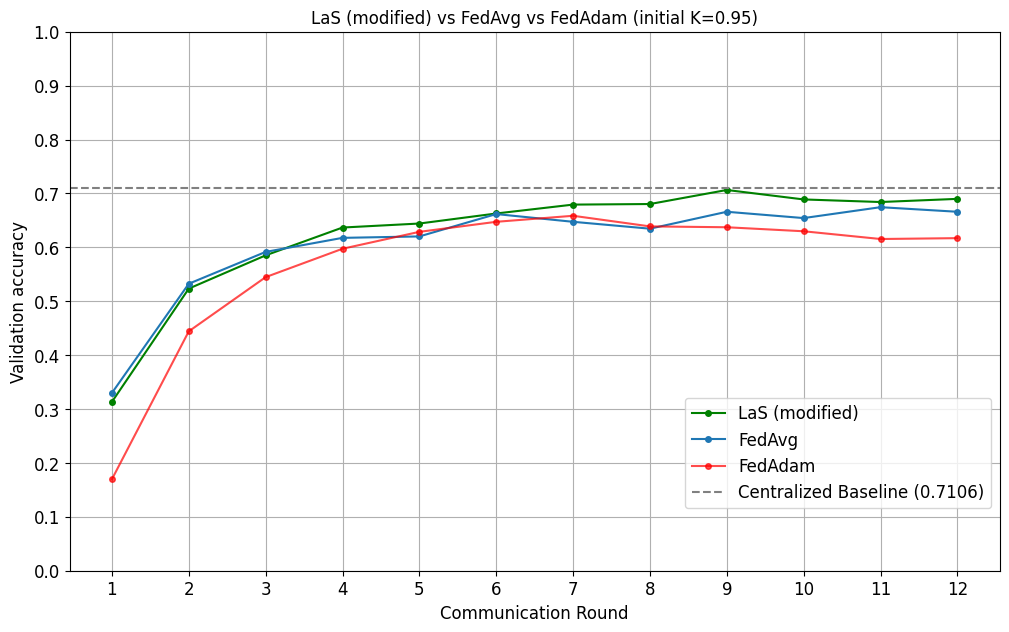

In [40]:
import matplotlib.pyplot as plt

x_values = range(1, ROUNDS+2)

plt.figure(figsize=(12, 7))
plt.plot(x_values, stitched_accuracy, label='LaS (modified)', color='green', marker='o', markersize=4)
plt.plot(x_values, fedavg_accuracy, label='FedAvg', marker='o', markersize=4)
plt.plot(x_values, fedadam_accuracy, label='FedAdam', color='red', alpha=0.7, marker='o', markersize=4)

# Add the baseline validation accuracy as a fixed dashed line
plt.axhline(y=baseline_acc, color='gray', linestyle='--', label=f'Centralized Baseline ({baseline_acc:.4f})')

plt.xlabel('Communication Round', fontsize='large')
plt.ylabel('Validation accuracy', fontsize='large')
plt.title('LaS (modified) vs FedAvg vs FedAdam (initial K=0.95)')

# Set x-axis ticks to integers
plt.xticks(x_values)

# Set y-axis ticks with increments of 0.1
plt.yticks([i / 10 for i in range(11)])
plt.tick_params(axis='both', labelsize='large')  # Increase tick font size

plt.ylim(0, 1)  # Set Y-axis limits from 0 to 1

# Move legend lower
plt.legend(loc='lower right', bbox_to_anchor=(1, 0.1), fontsize='large')
plt.grid(True)

# Save the plot as a vector image
plt.savefig('comparison_dtd.svg', format='svg')

plt.show()

### 10. Final test evaluation

Report test accuracy after all communication rounds. These scores do **not** control the retention schedule of $K$:

$$
K_t = 1 - \mu \times \text{validation accuracy}_{t-1}
$$

The test scores never enter this formula or affect training decisions, so the test set is an independent evaluation.

In [ ]:
final_test_accuracy = {
    "LaS (modified)": accuracy(stitched_model, test_loader),
    "FedAvg": accuracy(fedavg_model, test_loader),
    "FedAdam": accuracy(fedadam_model, test_loader),
    "Centralized": accuracy(baseline_model, test_loader),
}
final_test_accuracy

{'LaS (modified)': np.float64(0.7031914893617022),
 'FedAvg': np.float64(0.6696808510638298),
 'FedAdam': np.float64(0.6345744680851064),
 'Centralized': np.float64(0.725)}